# Notebook 02 — Corpus EDA and Data Validation

**Job of this notebook:** check that the corpora built in Notebook 01 are fit for a *plot-based* network analysis, and document the limits a reader must know about. It changes no data and creates no data files; it only writes tables, diagnostic figures and notes.

### What this notebook checks
| # | Check | Why it matters |
|---|-------|----------------|
| 1 | **Every number in the notes is read from the data** and `corpus_manifest.json`, never typed by hand: the semantic corpus uses ≥ 35-word overviews and ≥ 25 votes (20,091 films), and NB03 embeds the `overview` column. | Prevents wrong facts reaching the thesis text. |
| 2 | **One revenue percentile.** Section 6 compares two reference groups for the year-relative revenue percentile, so one definition can be chosen for NB05. | One definition of each variable. |
| 3 | **Analyses the network corpus** (`df_network_corpus.csv`, 19,919 films), which is what the thesis actually studies, alongside the full thesis corpus. | Describes the right population. |
| 4 | **Validity checks:** representativeness, plot-text quality (duplicate overviews, overviews naming their own film, non-English text), rating reliability by vote count, revenue missingness bias, success-signal correlations. | These are the validity questions an examiner of a plot-based network will ask. |
| 5 | One `CFG`, a safe Drive mount, graceful handling of optional files, one consistent figure style. | Reliability and readability. |

**Thesis figures** come from Notebook 08 (the thesis bricks). Figures here are diagnostic and are saved next to the table that holds their numbers.

In [1]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 1 — CONFIG
# ═══════════════════════════════════════════════════════════════════════════
CFG = {
    "project_dir": "/content/drive/MyDrive/thesis_movie_project",

    # thresholds used to interpret results (the corpus thresholds themselves are read
    # from corpus_manifest.json written by Notebook 01)
    "rating_vote_bins": [1, 5, 10, 25, 50, 100, 250, 1000, 10_000, 1_000_000],
    "high_revenue_cutoffs": [0.75, 0.80],      # NB05 uses 0.75; 0.80 shown for comparison
    # capitalised title words that are not names (ignored by the shared-name check)
    "title_word_stoplist": ["The", "This", "That", "With", "From", "Into", "Over", "Under", "Part", "Movie",
                            "Film", "Story", "Return", "Rise", "Love", "Last", "First", "Night", "Life",
                            "World", "Man", "Woman", "Girl", "Boy", "King", "Queen", "Dead", "House", "Home"],
    "top_n_genres": 15,
    "top_n_languages": 10,
    "figure_dpi": 200,
}
print("CONFIG loaded.")


CONFIG loaded.


In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 2 — Imports, Drive mount (idempotent), paths, figure style
# ═══════════════════════════════════════════════════════════════════════════
import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 100)
try:
    display
except NameError:
    display = print

import os, shutil, time
def mount_drive():
    """Mount Google Drive in Colab. Safe to re-run."""
    try:
        from google.colab import drive
    except ImportError:
        print("Not running in Colab — using local paths.")
        return
    if os.path.ismount("/content/drive"):          # a real Drive mount, not just a folder with that name
        print("Google Drive already mounted.")
        return
    # A plain folder at /content/drive (created while Drive was not connected) hides your Drive and blocks
    # mounting ("Mountpoint must not already contain files"). Move it aside — nothing on Drive is touched.
    if os.path.isdir("/content/drive") and os.listdir("/content/drive"):
        aside = f"/content/drive_local_leftover_{time.strftime('%Y%m%d_%H%M%S')}"
        shutil.move("/content/drive", aside)
        print(f"Moved a local leftover folder (not your Drive) to {aside}.")
    drive.mount("/content/drive")
mount_drive()

PROJECT_DIR = Path(CFG["project_dir"])
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check that Google Drive is mounted "
                            "(left sidebar → Files → drive/MyDrive) and that CFG['project_dir'] is right.")
CORE_DIR    = PROJECT_DIR / "processed" / "core"
NETWORK_DIR = PROJECT_DIR / "processed" / "network"
TABLES_DIR  = PROJECT_DIR / "outputs" / "tables"
EDA_TABLES  = TABLES_DIR / "eda"
EDA_FIGS    = PROJECT_DIR / "outputs" / "figures" / "eda"
for d in [EDA_TABLES, EDA_FIGS]:
    d.mkdir(parents=True, exist_ok=True)

# ── one figure style for the whole notebook (validated colour-blind-safe palette) ──
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed order: blue, orange, aqua, yellow
DIVERGING = "RdBu_r"                                    # blue ↔ red, neutral midpoint
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 24,
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.family": "DejaVu Sans", "lines.linewidth": 2, "legend.frameon": False,
})

def subtitle(ax, text):
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6), textcoords="offset points",
                fontsize=9.5, color=INK_2, va="bottom", ha="left")

def save(fig, table, name):
    """Every figure is saved with the table that holds its numbers."""
    fig.savefig(EDA_FIGS / f"{name}.png", dpi=CFG["figure_dpi"], bbox_inches="tight")
    table.to_csv(EDA_TABLES / f"{name}.csv", index=False)
    plt.show()
    print(f"  ✓ figures/eda/{name}.png + tables/eda/{name}.csv")

def save_table(table, name):
    table.to_csv(EDA_TABLES / f"{name}.csv", index=False)
    print(f"  ✓ tables/eda/{name}.csv")

print("PROJECT_DIR:", PROJECT_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project


In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3 — Load data (required files stop the notebook, optional ones are skipped)
# ═══════════════════════════════════════════════════════════════════════════
REQUIRED = {
    "thesis":   CORE_DIR / "df_thesis_films.csv",
    "semantic": CORE_DIR / "df_semantic_analysis.csv",
    "network":  CORE_DIR / "df_network_corpus.csv",
    "revenue":  CORE_DIR / "df_revenue_analysis.csv",
    "roi":      CORE_DIR / "df_roi_analysis.csv",
}
OPTIONAL = {
    "manifest":     CORE_DIR / "corpus_manifest.json",
    "funnel":       TABLES_DIR / "filtering_funnel.csv",
    "event_audit":  TABLES_DIR / "corpus_audit" / "event_filter_audit.csv",
    "network_lcc":  NETWORK_DIR / "semantic_network_nodes_lcc.csv",   # from NB03; may predate the new corpus
}
missing = [k for k, p in REQUIRED.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f"Run Notebook 01 first. Missing: {missing}")

D = {k: pd.read_csv(p, low_memory=False) for k, p in REQUIRED.items()}
for k, d in D.items():
    print(f"  ✓ {k:9s} {len(d):>7,} rows")

manifest = json.loads(OPTIONAL["manifest"].read_text()) if OPTIONAL["manifest"].exists() else None
funnel = pd.read_csv(OPTIONAL["funnel"]) if OPTIONAL["funnel"].exists() else None
event_audit = pd.read_csv(OPTIONAL["event_audit"]) if OPTIONAL["event_audit"].exists() else None
lcc = pd.read_csv(OPTIONAL["network_lcc"], usecols=["tmdb_id"]) if OPTIONAL["network_lcc"].exists() else None
for k, v in [("manifest", manifest), ("funnel", funnel), ("event_audit", event_audit), ("network_lcc", lcc)]:
    print(f"  {'✓' if v is not None else '–'} optional: {k}")

# Language and budget are only in the thesis table; attach them to the other corpora.
extra = D["thesis"][["tmdb_id", "original_language", "budget_clean"]]
for k in ["semantic", "network"]:
    D[k] = D[k].merge(extra, on="tmdb_id", how="left")

# ── consistency with what Notebook 01 says it wrote ──────────────────────────
if manifest:
    rows = manifest["row_counts"]
    name_map = {"thesis": "df_thesis_films", "semantic": "df_semantic_analysis", "network": "df_network_corpus",
                "revenue": "df_revenue_analysis", "roi": "df_roi_analysis"}
    bad = {name_map[k]: (rows.get(name_map[k]), len(d)) for k, d in D.items() if rows.get(name_map[k]) != len(d)}
    print("\nManifest consistency:", "OK" if not bad else f"MISMATCH {bad} — re-run Notebook 01")
    if lcc is not None and not set(lcc["tmdb_id"]) <= set(D["network"]["tmdb_id"]):
        print("Note: the network files from NB03 were built from an older corpus; re-run NB03.")
        lcc = None

# ── stale duplicates outside processed/core ─────────────────────────────────
stale = [p.name for p in (PROJECT_DIR / "processed").glob("df_*.csv")]
if stale:
    print("\n⚠ Old copies outside processed/core (not used by any notebook; consider archiving):", stale)


  ✓ thesis     98,037 rows
  ✓ semantic   20,091 rows
  ✓ network    19,919 rows
  ✓ revenue    13,186 rows
  ✓ roi         7,933 rows
  ✓ optional: manifest
  ✓ optional: funnel
  ✓ optional: event_audit
  ✓ optional: network_lcc

Manifest consistency: OK

⚠ Old copies outside processed/core (not used by any v2 notebook; consider archiving): ['df_semantic_core_v3.csv', 'df_network_compare_v3.csv', 'df_revenue_v3.csv', 'df_roi_v3.csv', 'df_semantic_core.csv', 'df_network_compare.csv', 'df_revenue.csv', 'df_roi.csv', 'df_semantic_interpretive.csv', 'df_semantic_analysis_lcc.csv', 'df_semantic_analysis.csv', 'df_revenue_analysis.csv', 'df_roi_analysis.csv']


## 1. Integrity and the full funnel

The thesis analyses the **network corpus**, so the funnel runs from the raw extract through the thesis corpus to the semantic and network stages (and the largest connected component once NB03 has run).

In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 4 — Integrity report
# ═══════════════════════════════════════════════════════════════════════════
def integrity(d, name):
    return {
        "dataset": name, "rows": len(d),
        "duplicate_tmdb_id": int(d["tmdb_id"].duplicated().sum()),
        "missing_title_pct": round(d["title"].isna().mean() * 100, 3),
        "missing_year_pct": round(d["release_year"].isna().mean() * 100, 3),
        "missing_or_empty_overview_pct": round((d["overview"].fillna("").str.strip() == "").mean() * 100, 3)
                                         if "overview" in d else np.nan,
        "year_range": f"{int(d['release_year'].min())}–{int(d['release_year'].max())}",
        "median_vote_count": d["vote_count"].median(),
    }
integrity_df = pd.DataFrame([integrity(d, k) for k, d in D.items()])
display(integrity_df)
save_table(integrity_df, "01_integrity_report")


,dataset,rows,duplicate_tmdb_id,missing_title_pct,missing_year_pct,missing_or_empty_overview_pct,year_range,median_vote_count
0,thesis,98037,0,0.0,0.0,0.0,1990–2024,7.0
1,semantic,20091,0,0.0,0.0,0.0,1990–2024,94.0
2,network,19919,0,0.0,0.0,0.0,1990–2024,95.0
3,revenue,13186,0,0.0,0.0,0.0,1990–2024,192.0
4,roi,7933,0,0.0,0.0,0.0,1990–2024,510.0


  ✓ tables/eda/01_integrity_report.csv


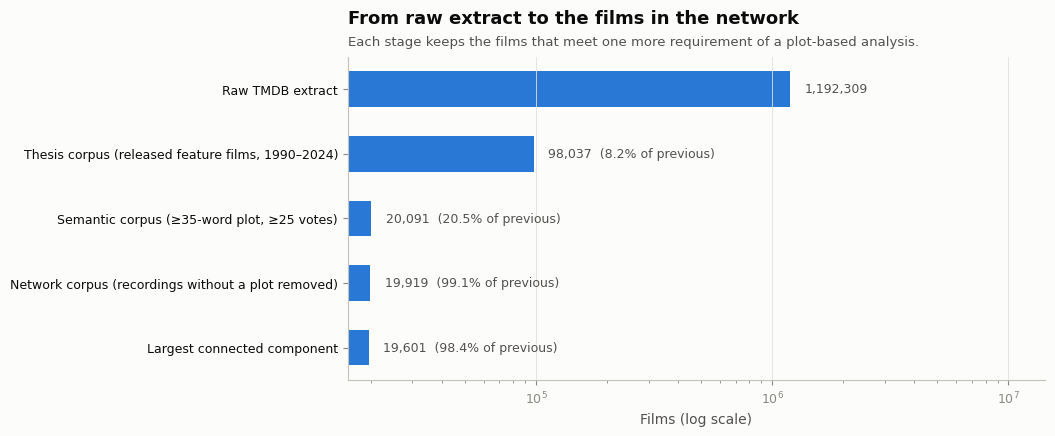

  ✓ figures/eda/02_full_funnel.png + tables/eda/02_full_funnel.csv


In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 5 — Full funnel: raw → thesis → semantic → network (→ LCC)
# ═══════════════════════════════════════════════════════════════════════════
stages = []
if funnel is not None:
    stages.append(("Raw TMDB extract", int(funnel["rows_after"].iloc[0])))
stages += [
    ("Thesis corpus (released feature films, 1990–2024)", len(D["thesis"])),
    ("Semantic corpus (≥35-word plot, ≥25 votes)", len(D["semantic"])),
    ("Network corpus (recordings without a plot removed)", len(D["network"])),
]
if lcc is not None:
    stages.append(("Largest connected component", len(lcc)))
full_funnel = pd.DataFrame(stages, columns=["stage", "films"])
full_funnel["pct_of_previous"] = (full_funnel["films"] / full_funnel["films"].shift() * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 0.6 * len(full_funnel) + 1.2))
y = np.arange(len(full_funnel))[::-1]
ax.barh(y, full_funnel["films"], color=SERIES[0], height=0.55)
ax.set_xscale("log")
ax.set_yticks(y, full_funnel["stage"], color=INK)
for yi, n, p in zip(y, full_funnel["films"], full_funnel["pct_of_previous"]):
    ax.text(n * 1.15, yi, f"{n:,}" + ("" if pd.isna(p) else f"  ({p:.1f}% of previous)"),
            va="center", fontsize=9, color=INK_2)
ax.set_xlim(right=full_funnel["films"].max() * 12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Films (log scale)")
ax.set_title("From raw extract to the films in the network")
subtitle(ax, "Each stage keeps the films that meet one more requirement of a plot-based analysis.")
save(fig, full_funnel, "02_full_funnel")


## 2. Representativeness — what kind of cinema does the network describe?

The semantic thresholds (≥25 votes, ≥35-word plot) keep films with an audience and a real plot description. That is the right choice for NLP, but it changes the mix of films. This section measures how, so the thesis can state which population its findings describe. A ratio above 1 means a group is over-represented in the network compared with the full thesis corpus.

,primary_genre,thesis_share_pct,network_share_pct,ratio_network_vs_thesis
0,Drama,32.47,26.46,0.81
1,Comedy,20.20,22.56,1.12
2,Action,9.15,11.42,1.25
3,Horror,8.66,9.11,1.05
4,Thriller,5.40,5.46,1.01
5,Romance,4.50,3.60,0.80
6,Music,4.30,0.95,0.22
7,Crime,3.31,3.76,1.13
8,Animation,2.53,4.36,1.73
9,Family,2.08,2.11,1.02


,release_year,thesis_share_pct,network_share_pct,ratio_network_vs_thesis
3,1990s,13.64,13.74,1.01
1,2000s,24.51,25.35,1.03
0,2010s,40.61,41.81,1.03
2,2020s,21.24,19.10,0.90


  ✓ tables/eda/03_representativeness_decade.csv


,original_language,thesis_share_pct,network_share_pct,ratio_network_vs_thesis
0,en,43.41,53.06,1.22
1,es,5.52,5.14,0.93
2,ja,5.51,4.82,0.87
3,fr,5.48,10.15,1.85
4,de,3.58,2.88,0.81
5,ko,3.08,2.17,0.70
6,zh,2.75,1.89,0.69
7,it,2.29,3.93,1.71
8,hi,2.22,1.62,0.73
9,ru,2.21,1.89,0.86


  ✓ tables/eda/03_representativeness_language.csv


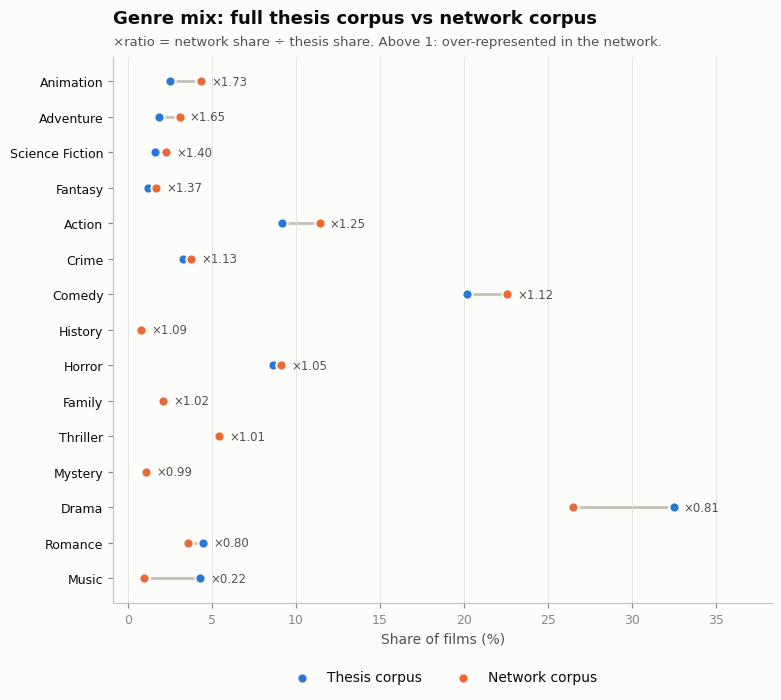

  ✓ figures/eda/03_representativeness_genre.png + tables/eda/03_representativeness_genre.csv


In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 6 — Representativeness: genre, decade, language
# ═══════════════════════════════════════════════════════════════════════════
def share_compare(col, top_n=None, transform=None):
    a = D["thesis"][col].pipe(transform) if transform else D["thesis"][col]
    b = D["network"][col].pipe(transform) if transform else D["network"][col]
    t = pd.DataFrame({"thesis_share_pct": a.value_counts(normalize=True) * 100,
                      "network_share_pct": b.value_counts(normalize=True) * 100}).fillna(0)
    t["ratio_network_vs_thesis"] = (t["network_share_pct"] / t["thesis_share_pct"]).round(2)
    t = t.sort_values("thesis_share_pct", ascending=False)
    if top_n:
        t = t.head(top_n)
    return t.round(2).rename_axis(col).reset_index()

decade = lambda s: (s // 10 * 10).astype("Int64").astype(str) + "s"
rep_genre    = share_compare("primary_genre", CFG["top_n_genres"])
rep_decade   = share_compare("release_year", transform=decade).sort_values("release_year")
rep_language = share_compare("original_language", CFG["top_n_languages"])
for name, t in [("03_representativeness_genre", rep_genre), ("03_representativeness_decade", rep_decade),
                ("03_representativeness_language", rep_language)]:
    display(t)
    if name != "03_representativeness_genre":
        save_table(t, name)

# Dumbbell chart for genre: where does the network over- or under-represent?
g = rep_genre.sort_values("ratio_network_vs_thesis")
fig, ax = plt.subplots(figsize=(8.5, 0.38 * len(g) + 1.4))
y = np.arange(len(g))
ax.hlines(y, g["thesis_share_pct"], g["network_share_pct"], color=AXIS, linewidth=2, zorder=1)
ax.scatter(g["thesis_share_pct"], y, s=55, color=SERIES[0], zorder=2, label="Thesis corpus",
           edgecolor=SURFACE, linewidth=1.5)
ax.scatter(g["network_share_pct"], y, s=55, color=SERIES[1], zorder=3, label="Network corpus",
           edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(y, g["primary_genre"], color=INK)
for yi, r in zip(y, g.itertuples()):
    ax.text(max(r.thesis_share_pct, r.network_share_pct) + 0.6, yi, f"×{r.ratio_network_vs_thesis:.2f}",
            va="center", fontsize=8.5, color=INK_2)
ax.set_xlabel("Share of films (%)")
ax.set_xlim(right=max(g["thesis_share_pct"].max(), g["network_share_pct"].max()) * 1.18)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2)
ax.set_title("Genre mix: full thesis corpus vs network corpus")
subtitle(ax, "×ratio = network share ÷ thesis share. Above 1: over-represented in the network.")
save(fig, rep_genre, "03_representativeness_genre")


## 3. Plot-text quality for the NLP step

The network connects films whose plot overviews are semantically similar. Four things can create similarity that is not about the story:
1. **Duplicate overviews** — two films with the same text become near-identical vectors and get an artificial edge.
2. **Names shared with the title** — an overview that repeats a name from the title (a franchise or character name such as *Potter*) lets the embedding group films by name rather than by plot. NB03 removed titles from the embedded text, but names inside the overview remain. This check measures how common that is.
3. **Non-English overviews** — the embedding model (all-MiniLM-L6-v2) is trained on English.
4. **Era drift in overview length** — if older films have systematically shorter descriptions, their vectors are less informative.

In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 7 — Plot-text quality checks on the network corpus
# ═══════════════════════════════════════════════════════════════════════════
N = D["network"].copy()
ov_norm = N["overview"].fillna("").str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True) \
                       .str.replace(r"\s+", " ", regex=True).str.strip()

# (1) duplicate overviews
dup_mask = ov_norm.duplicated(keep=False)
dup_groups = (N.loc[dup_mask, ["tmdb_id", "title", "release_year", "overview"]]
                .assign(group=ov_norm[dup_mask].factorize()[0])
                .sort_values(["group", "release_year"]))

# (2) overview repeats a proper name from the title (franchise/character names, e.g. "Potter")
#     Title names: capitalised words of 4+ letters, minus a stoplist of common title words.
#     Overview names: capitalised words NOT at the start of a sentence (so "Alien" ≠ "an alien world").
title_names = (N["title"].fillna("").str.findall(r"\b[A-Z][A-Za-z'’]{3,}\b").explode().dropna()
                 .loc[lambda s: ~s.isin(CFG["title_word_stoplist"])])
over_names = N["overview"].fillna("").str.findall(r"(?<=[a-z0-9,;:)] )([A-Z][A-Za-z'’]{3,})").explode().dropna()
shared = (pd.DataFrame({"name": title_names}).reset_index()
            .merge(pd.DataFrame({"name": over_names}).reset_index(), on=["index", "name"])
            .drop_duplicates())
self_mention = N.index.isin(shared["index"])
self_examples = (N.loc[self_mention, ["title", "release_year", "vote_count"]]
                   .join(shared.groupby("index")["name"].agg(", ".join).rename("shared_names"))
                   .sort_values("vote_count", ascending=False))

# (3) likely non-English overviews (share of Latin letters among non-space characters)
letters = N["overview"].str.count(r"[A-Za-z]")
non_space = N["overview"].str.count(r"\S").clip(lower=1)
non_english = (letters / non_space) < 0.6

text_quality = pd.DataFrame([
    {"check": "films in network corpus", "films": len(N), "pct": 100.0},
    {"check": "overview shared with another film (exact, after normalising)", "films": int(dup_mask.sum()),
     "pct": round(dup_mask.mean() * 100, 2)},
    {"check": "overview repeats a name from the title", "films": int(self_mention.sum()), "pct": round(self_mention.mean() * 100, 2)},
    {"check": "overview likely not English", "films": int(non_english.sum()), "pct": round(non_english.mean() * 100, 2)},
    {"check": "original language not English (overview usually still English)",
     "films": int(N["original_language"].ne("en").sum()), "pct": round(N["original_language"].ne("en").mean() * 100, 2)},
])
display(text_quality)
save_table(text_quality, "04_text_quality_summary")
save_table(dup_groups, "04_duplicate_overviews")
save_table(self_examples.reset_index(drop=True), "04_overviews_sharing_title_names")
print("\nDuplicate overview groups (first 10 rows):"); display(dup_groups.head(10))
print("\nMost-voted films whose overview repeats a name from the title:"); display(self_examples.head(10))


,check,films,pct
0,films in network corpus,19919,100.00
1,"overview shared with another film (exact, after normalising)",25,0.13
2,overview repeats a name from the title,4433,22.26
3,overview likely not English,0,0.00
4,original language not English (overview usually still English),9349,46.94


  ✓ tables/eda/04_text_quality_summary.csv
  ✓ tables/eda/04_duplicate_overviews.csv
  ✓ tables/eda/04_overviews_sharing_title_names.csv

Duplicate overview groups (first 10 rows):


,tmdb_id,title,release_year,overview,group
579,15300,Newsies,1992,"A week in the life of the exploited, child newspaper sellers in turn-of-the-century New York. Wh...",0
17881,462477,Newsies,2017,"A week in the life of the exploited, child newspaper sellers in turn-of-the-century New York. Wh...",0
1227,47257,A Christmas Carol,1997,Miser Ebenezer Scrooge is awakened on Christmas Eve by spirits who reveal to him his own miserab...,1
2969,16716,A Christmas Carol,1999,Miser Ebenezer Scrooge is awakened on Christmas Eve by spirits who reveal to him his own miserab...,1
7408,17979,A Christmas Carol,2009,Miser Ebenezer Scrooge is awakened on Christmas Eve by spirits who reveal to him his own miserab...,1
1589,47333,Jane Eyre,1996,"After a bleak childhood, Jane Eyre goes out into the world to become a governess. As she lives h...",2
8522,38684,Jane Eyre,2011,"After a bleak childhood, Jane Eyre goes out into the world to become a governess. As she lives h...",2
1741,50512,Anna Karenina,1997,"In Imperial Russia, Anna, wife of the officer Karenin, goes to Moscow to visit her brother. On t...",3
11537,96724,Anna Karenina,2012,"In Imperial Russia, Anna, wife of the officer Karenin, goes to Moscow to visit her brother. On t...",3
1769,40815,On Guard,1997,"France, 17th century, during the reign of Louis XIII. When a dear friend, the Duke of Nevers, is...",4



Most-voted films whose overview repeats a name from the title:


,title,release_year,vote_count,shared_names
9778,Deadpool,2016,32634.0,Deadpool
15965,Avengers: Infinity War,2018,31790.0,"Avengers, Infinity"
1121,The Shawshank Redemption,1994,30251.0,Shawshank
3128,Harry Potter and the Philosopher's Stone,2001,29457.0,"Harry, Potter"
15966,Avengers: Endgame,2019,27599.0,Avengers
2004,Titanic,1997,27067.0,Titanic
13425,Avengers: Age of Ultron,2015,24331.0,"Avengers, Ultron"
9280,The Dark Knight Rises,2012,24259.0,"Dark, Knight"
4352,Inglourious Basterds,2009,24076.0,Basterds
15236,Captain America: Civil War,2016,23932.0,"Captain, America"


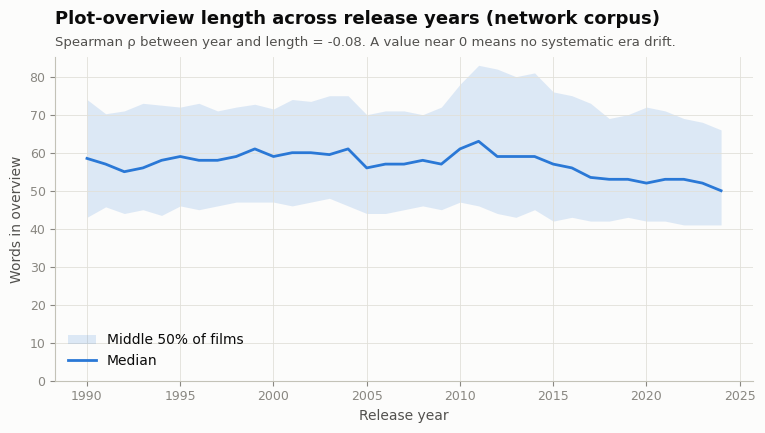

  ✓ figures/eda/05_overview_length_by_year.png + tables/eda/05_overview_length_by_year.csv


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 8 — Overview length by release year (era drift)
# ═══════════════════════════════════════════════════════════════════════════
by_year = (D["network"].groupby("release_year")["overview_word_count"]
             .agg(median="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75), films="size")
             .reset_index())
rho = D["network"][["release_year", "overview_word_count"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(by_year["release_year"], by_year["p25"], by_year["p75"], color=SERIES[0], alpha=0.15,
                linewidth=0, label="Middle 50% of films")
ax.plot(by_year["release_year"], by_year["median"], color=SERIES[0], label="Median")
ax.set_ylim(bottom=0)
ax.set_xlabel("Release year"); ax.set_ylabel("Words in overview")
ax.legend(loc="lower left")
ax.set_title("Plot-overview length across release years (network corpus)")
subtitle(ax, f"Spearman ρ between year and length = {rho:.2f}. A value near 0 means no systematic era drift.")
save(fig, by_year, "05_overview_length_by_year")


## 4. Rating reliability — why the vote-count threshold matters

`vote_average` is one of the success signals. A film rated by five people can easily average 9 or 2 by chance. This section shows how much ratings scatter at each vote-count level, which justifies the ≥25-vote threshold of the semantic corpus with data rather than by assertion.

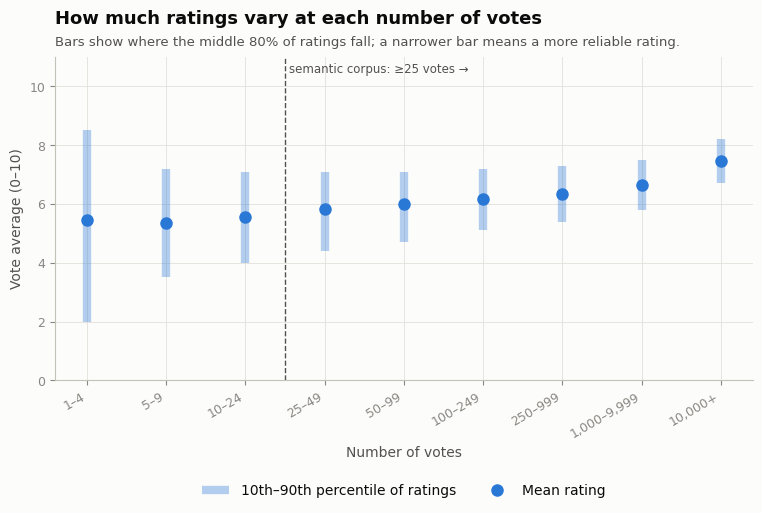

  ✓ figures/eda/06_rating_spread_by_votes.png + tables/eda/06_rating_spread_by_votes.csv


,min_votes,min_words,films,median_votes,median_words,revenue_available_pct,english_original_pct,chosen
0,10,35,32501,37.0,58.0,27.0,47.8,False
1,10,50,20915,35.0,71.0,26.3,46.5,False
2,10,75,9014,27.0,95.0,20.7,40.8,False
3,25,35,20091,94.0,57.0,39.3,53.3,True
4,25,50,12542,89.0,69.0,39.2,52.2,False
5,25,75,4735,70.0,92.0,33.5,45.0,False
6,50,35,13965,181.0,56.0,50.2,59.2,False
7,50,50,8570,174.0,67.0,50.6,58.4,False
8,50,75,2947,135.0,90.0,44.8,50.7,False
9,100,35,9781,338.0,55.0,61.9,65.3,False


  ✓ tables/eda/06_threshold_sensitivity.csv


In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 9 — Rating spread by vote count + threshold sensitivity
# ═══════════════════════════════════════════════════════════════════════════
T = D["thesis"][D["thesis"]["vote_count"] >= 1]
bins = CFG["rating_vote_bins"]
labels = [f"{a:,}–{b - 1:,}" for a, b in zip(bins[:-1], bins[1:])]
labels[-1] = f"{bins[-2]:,}+"
T = T.assign(vote_bin=pd.cut(T["vote_count"], bins=bins, right=False, labels=labels))
rating_spread = (T.groupby("vote_bin", observed=True)["vote_average"]
                   .agg(films="size", mean="mean", sd="std",
                        p10=lambda s: s.quantile(.10), p90=lambda s: s.quantile(.90))
                   .round(2).reset_index())
rating_spread["p10_p90_width"] = (rating_spread["p90"] - rating_spread["p10"]).round(2)

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(rating_spread))
ax.vlines(x, rating_spread["p10"], rating_spread["p90"], color=SERIES[0], linewidth=6, alpha=0.35,
          label="10th–90th percentile of ratings")
ax.plot(x, rating_spread["mean"], "o", color=SERIES[0], markersize=8, label="Mean rating")
lower = dict(zip(labels, bins[:-1]))
present_lower = [lower[str(b)] for b in rating_spread["vote_bin"]]
cut = next((i for i, lo in enumerate(present_lower) if lo >= 25), None)
ax.set_ylim(0, 11)
ax.set_yticks(range(0, 11, 2))
if cut is not None and cut > 0:
    ax.axvline(cut - 0.5, color=INK_2, linestyle="--", linewidth=1)
    ax.text(cut - 0.45, 10.8, "semantic corpus: ≥25 votes →", fontsize=8.5, color=INK_2, va="top")
ax.set_xticks(x, rating_spread["vote_bin"].astype(str), rotation=30, ha="right")
ax.set_xlabel("Number of votes"); ax.set_ylabel("Vote average (0–10)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
ax.set_title("How much ratings vary at each number of votes")
subtitle(ax, "Bars show where the middle 80% of ratings fall; a narrower bar means a more reliable rating.")
save(fig, rating_spread, "06_rating_spread_by_votes")

# Threshold sensitivity (with the network-relevant columns)
sens = []
for v in [10, 25, 50, 100]:
    for w in [35, 50, 75]:
        t = D["thesis"][(D["thesis"]["vote_count"].fillna(0) >= v) & (D["thesis"]["overview_word_count"] >= w)]
        sens.append({"min_votes": v, "min_words": w, "films": len(t),
                     "median_votes": t["vote_count"].median(), "median_words": t["overview_word_count"].median(),
                     "revenue_available_pct": round(t["revenue_clean"].notna().mean() * 100, 1),
                     "english_original_pct": round(t["original_language"].eq("en").mean() * 100, 1),
                     "chosen": (v == 25 and w == 35)})
sensitivity = pd.DataFrame(sens)
display(sensitivity)
save_table(sensitivity, "06_threshold_sensitivity")


## 5. Success signals — availability, missingness bias, and how they relate

The thesis treats success as multidimensional. Before modelling, three facts need to be on record:
* how many network films have each signal;
* whether films **with** revenue data differ from films **without** it (if they do, commercial results describe a selected subset, not the whole network);
* how strongly the signals move together (weak correlations are the empirical basis for calling success multidimensional).

,signal,films_available,pct
0,vote average,19919,100.0
1,vote count,19919,100.0
2,popularity,19919,100.0
3,revenue,7876,39.5
4,budget,6925,34.8


  ✓ tables/eda/07_success_signal_availability.csv


,group,films,median_vote_count,median_vote_average,median_popularity,english_original_pct,median_release_year,drama_primary_pct,action_primary_pct
0,with revenue,7876,361.0,6.4,2.53,65.0,2010.0,24.8,14.1
1,without revenue,12043,58.0,6.0,1.25,45.3,2014.0,27.5,9.7


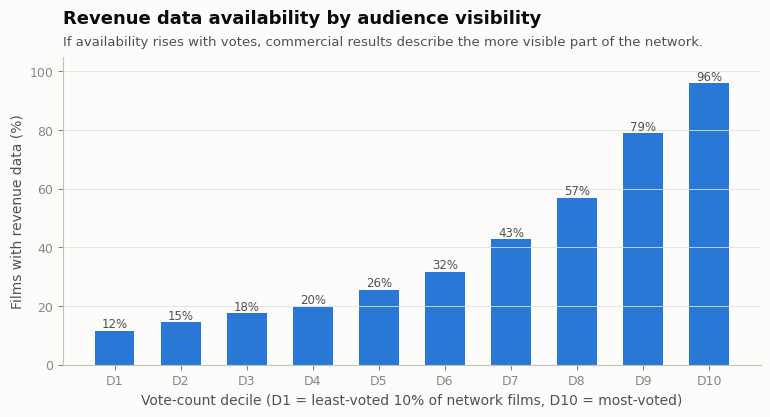

  ✓ figures/eda/07_revenue_availability_by_visibility.png + tables/eda/07_revenue_availability_by_visibility.csv
  ✓ tables/eda/07_revenue_missingness_profile.csv


In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 10 — Availability and revenue-missingness bias (network corpus)
# ═══════════════════════════════════════════════════════════════════════════
N = D["network"]
availability = pd.DataFrame([
    {"signal": s, "films_available": int(N[c].notna().sum()), "pct": round(N[c].notna().mean() * 100, 1)}
    for s, c in [("vote average", "vote_average"), ("vote count", "vote_count"), ("popularity", "popularity"),
                 ("revenue", "revenue_clean"), ("budget", "budget_clean")]
])
display(availability)
save_table(availability, "07_success_signal_availability")

has_rev = N["revenue_clean"].notna()
def profile(mask, label):
    s = N[mask]
    return {"group": label, "films": int(mask.sum()),
            "median_vote_count": s["vote_count"].median(),
            "median_vote_average": round(s["vote_average"].median(), 2),
            "median_popularity": round(s["popularity"].median(), 2),
            "english_original_pct": round(s["original_language"].eq("en").mean() * 100, 1),
            "median_release_year": s["release_year"].median(),
            "drama_primary_pct": round(s["primary_genre"].eq("Drama").mean() * 100, 1),
            "action_primary_pct": round(s["primary_genre"].eq("Action").mean() * 100, 1)}
missingness = pd.DataFrame([profile(has_rev, "with revenue"), profile(~has_rev, "without revenue")])
display(missingness)

# Revenue availability by audience-visibility decile: is missingness tied to visibility?
dec = pd.qcut(N["vote_count"].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
by_decile = (N.assign(decile=dec, has_revenue=has_rev).groupby("decile", observed=True)
               .agg(films=("has_revenue", "size"), revenue_available_pct=("has_revenue", "mean"),
                    median_votes=("vote_count", "median"))
               .reset_index())
by_decile["revenue_available_pct"] = (by_decile["revenue_available_pct"] * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(by_decile["decile"].astype(str), by_decile["revenue_available_pct"], color=SERIES[0], width=0.6)
for b, v in zip(bars, by_decile["revenue_available_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=8.5, color=INK_2)
ax.set_ylim(0, 105)
ax.set_xlabel("Vote-count decile (D1 = least-voted 10% of network films, D10 = most-voted)")
ax.set_ylabel("Films with revenue data (%)")
ax.grid(axis="x", visible=False)
ax.set_title("Revenue data availability by audience visibility")
subtitle(ax, "If availability rises with votes, commercial results describe the more visible part of the network.")
save(fig, by_decile, "07_revenue_availability_by_visibility")
save_table(missingness, "07_revenue_missingness_profile")


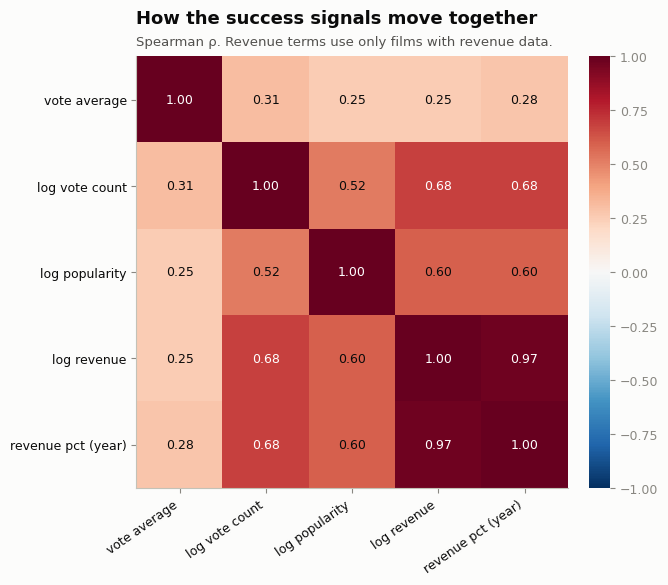

  ✓ figures/eda/08_success_signal_correlations.png + tables/eda/08_success_signal_correlations.csv
  ✓ tables/eda/08_success_signal_pair_counts.csv


In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 11 — How the success signals relate (Spearman, network corpus)
# ═══════════════════════════════════════════════════════════════════════════
S = pd.DataFrame({
    "vote average":   N["vote_average"],
    "log vote count": np.log1p(N["vote_count"]),
    "log popularity": np.log1p(N["popularity"]),
    "log revenue":    np.log1p(N["revenue_clean"]),
    "revenue pct (year)": N.groupby("release_year")["revenue_clean"].rank(pct=True),
})
corr = S.corr(method="spearman", min_periods=200).round(2)
pairs_n = S.notna().astype(int).T.dot(S.notna().astype(int))

fig, ax = plt.subplots(figsize=(6.8, 5.6))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha="right", color=INK)
ax.set_yticks(range(len(corr)), corr.index, color=INK)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.outline.set_visible(False); cb.ax.tick_params(colors=MUTED)
ax.set_title("How the success signals move together")
subtitle(ax, "Spearman ρ. Revenue terms use only films with revenue data.")
corr_table = corr.rename_axis("signal").reset_index()
save(fig, corr_table, "08_success_signal_correlations")
save_table(pairs_n.rename_axis("signal").reset_index(), "08_success_signal_pair_counts")


## 6. Which revenue percentile should NB05 use?

A year-relative revenue percentile removes inflation and differences in market size between years. It depends on **which films a film is ranked against**:
* **Market reference** — all thesis-corpus films released that year that report revenue.
* **Network reference** — only network films released that year.

The market reference is the better definition of commercial standing: a film's rank should not change because another film failed the plot-text filter. This cell measures how much the choice matters, so the decision can be stated in the Methods chapter.

In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 12 — Compare the two revenue-percentile definitions
# ═══════════════════════════════════════════════════════════════════════════
market = D["thesis"][D["thesis"]["revenue_clean"].notna()][["tmdb_id", "release_year", "revenue_clean"]].copy()
market["pct_market"] = market.groupby("release_year")["revenue_clean"].rank(pct=True)
net = N[N["revenue_clean"].notna()][["tmdb_id", "release_year", "revenue_clean"]].copy()
net["pct_network"] = net.groupby("release_year")["revenue_clean"].rank(pct=True)
cmp = net.merge(market[["tmdb_id", "pct_market"]], on="tmdb_id", how="left")

rows = [{"measure": "network films with revenue", "value": len(cmp)},
        {"measure": "Spearman ρ between definitions", "value": round(cmp[["pct_network", "pct_market"]].corr("spearman").iloc[0, 1], 3)},
        {"measure": "mean absolute difference (percentile points)", "value": round((cmp["pct_network"] - cmp["pct_market"]).abs().mean() * 100, 1)},
        {"measure": "median network percentile of these films in the MARKET reference", "value": round(cmp["pct_market"].median(), 3)}]
for c in CFG["high_revenue_cutoffs"]:
    flip = ((cmp["pct_network"] >= c) != (cmp["pct_market"] >= c)).mean() * 100
    rows.append({"measure": f"films whose 'high revenue' flag (≥{c:.2f}) differs", "value": f"{flip:.1f}%"})
pct_compare = pd.DataFrame(rows)
display(pct_compare)
save_table(pct_compare, "09_revenue_percentile_definitions")


,measure,value
0,network films with revenue,7876
1,Spearman ρ between definitions,0.997
2,mean absolute difference (percentile points),6.3
3,median network percentile of these films in the MARKET reference,0.588
4,films whose 'high revenue' flag (≥0.75) differs,6.4%
5,films whose 'high revenue' flag (≥0.80) differs,5.3%


  ✓ tables/eda/09_revenue_percentile_definitions.csv


## 7. Summary notes for the Data chapter

Every number below is computed from the files and from `corpus_manifest.json`; nothing is typed by hand.

In [13]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 13 — Auto-generated notes (facts only, from data)
# ═══════════════════════════════════════════════════════════════════════════
cfg01 = manifest["config"] if manifest else {}
embedded = manifest.get("embedded_text_column_in_nb03", "overview") if manifest else "overview"
tq = text_quality.set_index("check")["films"]
ratio = rep_genre.set_index("primary_genre")["ratio_network_vs_thesis"]
over, under = ratio.idxmax(), ratio.idxmin()
rs = rating_spread.set_index("vote_bin")["p10_p90_width"]
rev_row = missingness.set_index("group")

lines = [
    f"The thesis corpus contains {len(D['thesis']):,} released feature films "
    f"({int(D['thesis']['release_year'].min())}–{int(D['thesis']['release_year'].max())}).",
    f"The semantic corpus keeps films with at least {cfg01.get('overview_words_semantic', 35)} words of plot description "
    f"and at least {cfg01.get('vote_count_semantic', 25)} votes: {len(D['semantic']):,} films.",
    f"After removing recordings without a plot (wrestling and MMA broadcasts, concert films, stand-up specials), "
    f"the network corpus contains {len(D['network']):,} films.",
    f"Films are embedded from their plot overview only (`{embedded}`), not from titles, genres or cast.",
    f"Compared with the thesis corpus, the network over-represents {over} (×{ratio[over]:.2f}) and "
    f"under-represents {under} (×{ratio[under]:.2f}) among the {CFG['top_n_genres']} largest primary genres.",
    f"{int(tq.iloc[1]):,} network films share an identical overview with another film, and "
    f"{int(tq.iloc[2]):,} overviews repeat a proper name from their own title, such as a franchise or character name "
    f"(each can create similarity that is not about the plot).",
    f"The middle 80% of ratings spans {rs.iloc[0]:.1f} points for films with {rs.index[0]} votes and "
    f"{rs.iloc[-1]:.1f} points for films with {rs.index[-1]} votes"
    + (" — ratings from few votes are much noisier, which supports the vote threshold." if rs.iloc[0] > 1.5 * rs.iloc[-1] else "."),
]
# Interpretive clauses are added only when the numbers support them.
v_with, v_without = rev_row.loc["with revenue", "median_vote_count"], rev_row.loc["without revenue", "median_vote_count"]
lines.append(
    f"Revenue is available for {availability.set_index('signal').loc['revenue', 'pct']:.1f}% of network films. "
    f"Films with revenue have a median of {v_with:,.0f} votes versus {v_without:,.0f} without"
    + (", so commercial results describe the more visible part of the network." if v_with > 1.5 * v_without else "."))
rho_vr = corr.loc["vote average", "log revenue"]
if pd.notna(rho_vr):
    lines.append(f"Spearman ρ between vote average and log revenue is {rho_vr:.2f}"
                 + ("; the signals are only partly related, which supports treating success as multidimensional."
                    if abs(rho_vr) < 0.5 else "."))
notes = "\n".join(f"- {l}" for l in lines)
print(notes)
(EDA_TABLES / "eda_summary_notes.md").write_text(notes, encoding="utf-8")
print("\n  ✓ tables/eda/eda_summary_notes.md")


- The thesis corpus contains 98,037 released feature films (1990–2024).
- The semantic corpus keeps films with at least 35 words of plot description and at least 25 votes: 20,091 films.
- After removing recordings without a plot (wrestling and MMA broadcasts, concert films, stand-up specials), the network corpus contains 19,919 films.
- Films are embedded from their plot overview only (`overview`), not from titles, genres or cast.
- Compared with the thesis corpus, the network over-represents Animation (×1.73) and under-represents Music (×0.22) among the 15 largest primary genres.
- 25 network films share an identical overview with another film, and 4,433 overviews repeat a proper name from their own title, such as a franchise or character name (each can create similarity that is not about the plot).
- The middle 80% of ratings spans 6.5 points for films with 1–4 votes and 1.5 points for films with 10,000+ votes — ratings from few votes are much noisier, which supports the vote thresho

In [14]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 14 — Output check
# ═══════════════════════════════════════════════════════════════════════════
out = sorted([("figure", p.name) for p in EDA_FIGS.glob("*.png")] +
             [("table", p.name) for p in EDA_TABLES.glob("*.*")])
display(pd.DataFrame(out, columns=["type", "file"]))


,type,file
0,figure,02_full_funnel.png
1,figure,03_representativeness_genre.png
2,figure,05_overview_length_by_year.png
3,figure,06_rating_spread_by_votes.png
4,figure,07_revenue_availability_by_visibility.png
5,figure,08_success_signal_correlations.png
6,table,01_integrity_report.csv
7,table,02_full_funnel.csv
8,table,03_representativeness_decade.csv
9,table,03_representativeness_genre.csv


## What comes next

* **Notebook 03** builds the network from `df_network_corpus.csv`. If Section 3 found many duplicate or self-naming overviews, NB03 reports how many network edges they create, so they are handled there rather than by removing films here.
* **Notebook 05** uses the **market-reference** revenue percentile from Section 6, with one "high revenue" cut-off (top 25%).